In [55]:
from setup_paths import SRC_DIR, DATA_DIR, RAW_DATA_DIR, PROCESSED_DATA_DIR, FIGURES_DIR 
from OpenFOAM_reader import extract_profile_from_openfoam

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from OpenFOAM_reader import extract_profile_from_openfoam


In [56]:
# OpenFOAM case settings
# CASE_PATH = '/home/vita/OpenFOAM/Test_case_Cube/Cube_SIMPLE_kOmegaSST_Uprofile_10_ABLcLam_U5_kcoded_LowReWallFunc_fineMesh/'  
CASE_PATH = RAW_DATA_DIR / 'Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1'

TIME = 'latestTime'     # solution time: '10000', '2', 'latestTime' 

X_LOCATIONS = np.array([                            # Define x-locations for profile extraction
    0.0000000,      # Inlet
    0.0375000,      # Non-disturbed flow
    0.0650000,      # In front of the cube
    0.0750000,      # Front face of the cube
    0.0825000,      # Top mid of the cube
    0.0903125,      # Just behind the cube
    0.1050000,      # Near wake:    1*Hc
    0.1200000,      # Further Wake: 2*Hc
    0.1350000,      # Further Wake: 3*Hc
    0.1500000,      # Far wake:     4*Hc
    0.3150000       # Outlet
])

# Y_LOCATION = None       # None = centerplane, or specify y-coordinate
Y_LOCATION = 0.0825                    # Centerplane
# TOLERANCE =  0.0003125  # Search tolerance for finding points - fine mesh dx
# TOLERANCE =  0.0006250  # Search tolerance for finding points - mid mesh dx
TOLERANCE =  0.0012500  # Search tolerance for finding points - coarse mesh dx

# ============================================
# LOAD DATA FROM OPENFOAM
# ============================================

print("="*60)
print("LOADING DATA FROM OPENFOAM")
print("="*60)
print(f"Case: {CASE_PATH}")
print(f"Time: {TIME}")
print("="*60 + "\n")

# Extract profiles
print(f"Extracting profiles at {len(X_LOCATIONS)} x-locations:")
for i, x_loc in enumerate(X_LOCATIONS):
    print(f"  {i+1}. x = {x_loc:.6f} m")
print()

all_profiles = {}

for x_loc in X_LOCATIONS:
    print(f"Extracting profile at x = {x_loc:.6f}...")
    
    z_prof, Ux_prof, Uy_prof, Uz_prof = extract_profile_from_openfoam(
        case_path=CASE_PATH,
        x_location=x_loc,
        time=TIME,
        y_location=Y_LOCATION,
        tolerance=TOLERANCE,
        method='closest',           # 'average' or 'closest' or 'all' (=raw)
        n_bins=100                      # for 'average' method = how many points to have after averaging 
    )
    
    if z_prof is not None:
        all_profiles[x_loc] = {
            'z': z_prof,
            'U_x': Ux_prof,
            'U_y': Uy_prof,
            'U_z': Uz_prof,
            'n_points': len(z_prof)
        }
        print(f"  ✓ Extracted {len(z_prof)} points")
    else:
        print(f"  ✗ Failed to extract profile at x = {x_loc}")
    print()
    
    

# Check if data was loaded
if z_prof is not None:
    print("="*100)
    print(f"SUCCESFULLY extracted {len(all_profiles)} profiles")


LOADING DATA FROM OPENFOAM
Case: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1
Time: latestTime

Extracting profiles at 11 x-locations:
  1. x = 0.000000 m
  2. x = 0.037500 m
  3. x = 0.065000 m
  4. x = 0.075000 m
  5. x = 0.082500 m
  6. x = 0.090313 m
  7. x = 0.105000 m
  8. x = 0.120000 m
  9. x = 0.135000 m
  10. x = 0.150000 m
  11. x = 0.315000 m

Extracting profile at x = 0.000000...
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/U
Reading 5,085,284 cells...

Extracted 304 points near x=0.0
  and y=0.0825
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.978107, 1.008990] m/s

  ✓ Extracted 55 points

Ex

Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/U
Reading 5,085,284 cells...

Extracted 608 points near x=0.135
  and y=0.0825
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [-0.123103, 1.153220] m/s

  ✓ Extracted 55 points

Extracting profile at x = 0.150000...
READING OPENFOAM DATA
Reading cell centers from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/C
Reading 5,085,284 cells...
Reading field from: /home/vita/ML/DACI/Multi_Case_CFD/data/raw/Cube_SIMPLE_kOmegaSST_Uprofile_4_Uniform_U1/10000/U
Reading 5,085,284 cells...

Extracted 608 points near x=0.15
  and y=0.0825
  Reduced to 55 points (closest at each height)

PROFILE EXTRACTED
Method: closest
Points in profile: 55
z range: [0.000313, 0.048125] m
U_x range: [0.067968, 1.142620] m/s

  ✓ Extracted 55 points

Extractin

In [57]:
# PREPARE TRAINING DATA FOR NETWORK FOR ALL PROFILES
   # Sample training points to create unified training dataset (2D)

print("="*70)
print("PREPARING UNIFIED TRAINING DATASET")
print("="*70)

# Cube geometry
H_CUBE = 0.015  # Cube height [m]
X_CUBE_FRONT = 0.075
X_CUBE_BACK = 0.090
U_BULK_INLET = 5.0  # [m/s]




# Collect all training data from all x-locations
all_X_features = []
all_y_velocities = []

n_points_per_profile = 50

training_data = {}

for x_loc, profile_data in all_profiles.items():
    z_full = profile_data['z']
    Ux_full = profile_data['U_x']
    
    # Sample points
    indices = np.linspace(0, len(z_full)-1, n_points_per_profile, dtype=int)
    z_sample = z_full[indices]
    Ux_sample = Ux_full[indices]
    
    print(f"\nProcessing x = {x_loc:.4f}:")
    
    # Create features for each point  (distance-based features)
    for z_point, ux_point in zip(z_sample, Ux_sample):
        
        # Normalized coordinates with respect to the cube's height
        x_norm = x_loc / H_CUBE
        z_norm = z_point / H_CUBE
        
        # Distance from cube
        x_cube_center = (X_CUBE_FRONT + X_CUBE_BACK) / 2
        dx_from_cube = (x_loc - x_cube_center) / H_CUBE
        
        # Relative position
        if x_loc < X_CUBE_FRONT:
            x_rel = (x_loc - X_CUBE_FRONT) / H_CUBE
        elif x_loc <= X_CUBE_BACK:
            x_rel = 0.0
        else:
            x_rel = (x_loc - X_CUBE_BACK) / H_CUBE
            
        # Wake indicator
        in_wake = 1.0 if x_loc > X_CUBE_BACK else 0.0
    
        # U_bulk normalized
        u_bulk_norm = U_BULK_INLET / U_BULK_INLET
        
        # Stack features: [x_norm, z_norm, dx_from_cube, x_rel, in_wake, u_bulk_norm]
        features = [x_norm, z_norm, u_bulk_norm]
#         features = [x_norm, z_norm, dx_from_cube, x_rel, in_wake, u_bulk_norm]
        
        all_X_features.append(features)
        all_y_velocities.append(ux_point)
    
    # Convert to tensors
    X_train = torch.tensor(all_X_features, dtype=torch.float32)
    y_train = torch.tensor(all_y_velocities, dtype=torch.float32).reshape(-1, 1)
    
    # Store normalization parameters and both original and normalized data
    training_data[x_loc] = {
        'X_train': X_train,                    # 2D input: [z_normalized, u_bulk_normalized]
        'y_train': y_train,
        'z_full': z_full,                      # Full profile for comparison
        'Ux_full': Ux_full,
        'z_sample': z_sample,                    # Original (non-normalized) z for plotting
        'Ux_sample': Ux_sample,
        'u_bulk': U_BULK_INLET                 # Store bulk velocity
    }
    
    
print(f"Total training points: {len(X_train)}")
print(f"Input features per point: {X_train.shape[1]}")
print(f"  - x_norm: streamwise position / H_cube")
print(f"  - z_norm: height / H_cube")
print(f"  - dx_from_cube: distance from cube center")
print(f"  - x_rel: relative position (upstream/over/wake)")
print(f"  - in_wake: boolean wake indicator")
print(f"  - u_bulk_norm: inlet velocity (normalized)")
print(f"\nX_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print("="*70 + "\n")

PREPARING UNIFIED TRAINING DATASET

Processing x = 0.0000:

Processing x = 0.0375:

Processing x = 0.0650:

Processing x = 0.0750:

Processing x = 0.0825:

Processing x = 0.0903:

Processing x = 0.1050:

Processing x = 0.1200:

Processing x = 0.1350:

Processing x = 0.1500:

Processing x = 0.3150:
Total training points: 550
Input features per point: 3
  - x_norm: streamwise position / H_cube
  - z_norm: height / H_cube
  - dx_from_cube: distance from cube center
  - x_rel: relative position (upstream/over/wake)
  - in_wake: boolean wake indicator
  - u_bulk_norm: inlet velocity (normalized)

X_train shape: torch.Size([550, 3])
y_train shape: torch.Size([550, 1])



In [58]:
# Choosing Appropriate Network Size:

# Get the total number of training points 
n_train = len(X_train)
print(f'Training points: {n_train}')

max_params = n_train // 5  # Conservative
print(f"Safe parameter budget: {max_params}")

# Number of layers:
    # A single hidden layer with enough neurons can approximate ANY continuous function!
print('\nA single hidden layer with enough neurons can approximate ANY continuous function!\n')

# Number of neurons:
def calculate_params(n_hidden):
    layer1 = (2 * n_hidden) + n_hidden  # input → hidden
    layer2 = (n_hidden * 1) + 1         # hidden → output
    return layer1 + layer2

# Find max hidden neurons
for n_h in range(1, max_params):
    params = calculate_params(n_h)
    if params > max_params:
        print(f"Max safe hidden neurons: {n_h - 1} ({calculate_params(n_h-1)} params)")
        break


Training points: 550
Safe parameter budget: 110

A single hidden layer with enough neurons can approximate ANY continuous function!

Max safe hidden neurons: 27 (109 params)


In [59]:
# NETWORK ARCHITECHTURES:


# UNIFIED NETWORK FOR ALL PROFILES

class UnifiedFlowNet(nn.Module):
    """
    Single network that learns flow at all x-locations
    Input: [x_norm, z_norm, dx_from_cube, x_rel, in_wake, u_bulk_norm]
    Output: U_x velocity
    """
    def __init__(self, n_inputs=3, hidden_size=50, n_layers=3):
        super().__init__()
        
        layers = []
        
        # Input layer
        layers.append(nn.Linear(n_inputs, hidden_size))
        layers.append(nn.Tanh())
        
        # Hidden layers
        for _ in range(n_layers - 1):
            layers.append(nn.Linear(hidden_size, hidden_size))
            layers.append(nn.Tanh())
        
        # Output layer
        layers.append(nn.Linear(hidden_size, 1))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)

# Create model
model = UnifiedFlowNet(n_inputs=3, hidden_size=50, n_layers=3)

n_params = sum(p.numel() for p in model.parameters())
print(f"Unified network created:")
print(f"  Model: {model}")
print(f"  Total parameters: {n_params}")


Unified network created:
  Model: UnifiedFlowNet(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=50, bias=True)
    (1): Tanh()
    (2): Linear(in_features=50, out_features=50, bias=True)
    (3): Tanh()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): Tanh()
    (6): Linear(in_features=50, out_features=1, bias=True)
  )
)
  Total parameters: 5351


TRAINING UNIFIED NETWORK
Epoch 0: Loss = 1.482696, LR = 0.010000
Epoch 50: Loss = 0.064554, LR = 0.010000
Epoch 100: Loss = 0.037897, LR = 0.010000
Epoch 150: Loss = 0.025460, LR = 0.010000
Epoch 200: Loss = 0.017970, LR = 0.010000
Epoch 250: Loss = 0.015086, LR = 0.010000
Epoch 300: Loss = 0.012385, LR = 0.010000
Epoch 350: Loss = 0.010871, LR = 0.010000
Epoch 400: Loss = 0.009227, LR = 0.010000
Epoch 450: Loss = 0.008110, LR = 0.010000
Epoch 500: Loss = 0.007193, LR = 0.010000
Epoch 550: Loss = 0.006184, LR = 0.010000
Epoch 600: Loss = 0.006064, LR = 0.010000
Epoch 650: Loss = 0.004769, LR = 0.010000
Epoch 700: Loss = 0.004022, LR = 0.010000
Epoch 750: Loss = 0.003261, LR = 0.010000
Epoch 800: Loss = 0.003930, LR = 0.010000
Epoch 850: Loss = 0.002278, LR = 0.010000
Epoch 900: Loss = 0.001952, LR = 0.010000
Epoch 950: Loss = 0.001850, LR = 0.010000
Epoch 1000: Loss = 0.001495, LR = 0.010000
Final loss: 0.001495

  Final RMSE: 0.039289 m/s
  Final MAE:  0.024421 m/s
  Max error:  0.231

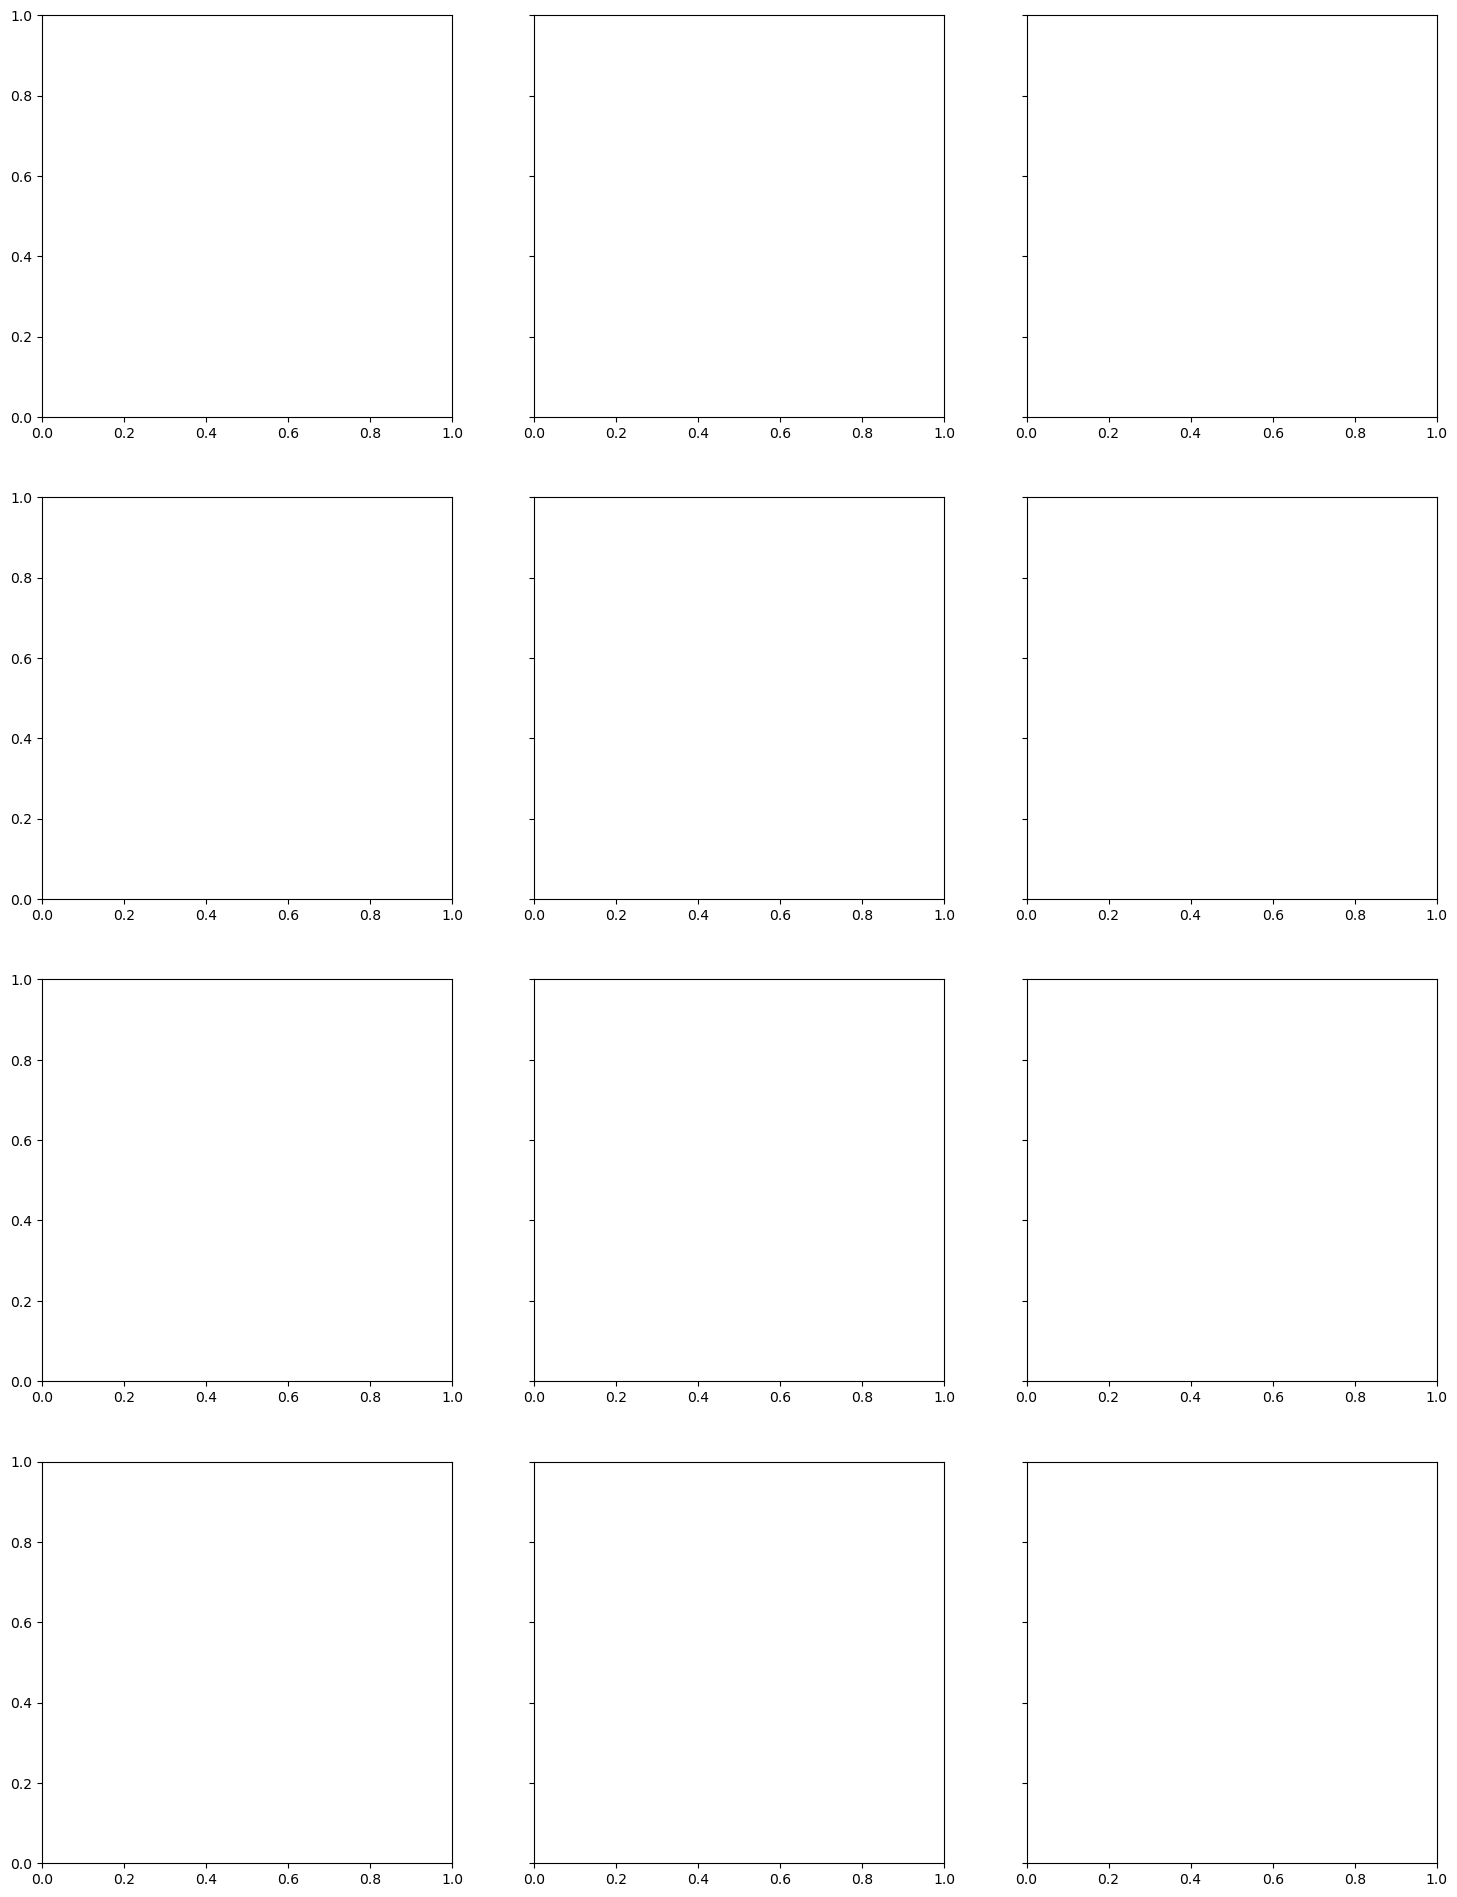

In [60]:
# TRAINING

print("="*70)
print("TRAINING UNIFIED NETWORK")
print("="*70)

# Optimizer for model (created in previous section)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2000, min_lr=1e-6
)

# Loss Function
criterion = nn.MSELoss()

# Training parameters
max_epochs = 1001     # CHANGE -> 100K?   
learning_rates = [] 
losses = []
best_loss = float('inf')
patience = 5000                                  # stop if no improvement for 5000 epochs
stopping_counter = 0
min_delta = 1e-7


# Visualization config
n_profiles = len(training_data)
n_cols = min(3, n_profiles)
n_rows = int(np.ceil(n_profiles / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 6*n_rows), 
                         squeeze=False, sharey=True)
axes = axes.flatten()

# Training loop
for epoch in range(max_epochs):
    # Training forward step
    y_pred = model(X_train)                    # forward pass: predict u
    loss = criterion(y_pred, y_train)          # calculate error
    
    # Training backpropagation
    optimizer.zero_grad()                      # clear old gradients
    loss.backward()                            # compute gradients (= how to change weights) by backpropagation 
    optimizer.step()                           # update weights based on computed gradients
    scheduler.step(loss)                       # adjust the learning rate based on training progress
    
    # Record loss
    losses.append(loss.item())
    current_loss = loss.item()                 # loss in a given round
    
    # Record learning rate
    current_lr = optimizer.param_groups[0]['lr']
    learning_rates.append(current_lr)          
    
    # Early stopping
    if best_loss - current_loss > min_delta:
        best_loss = current_loss
        stopping_counter = 0
    else:
        stopping_counter += 1
    
    # Epoch print
    if epoch % 50 == 0:  # CHANGE to 5K, if max_epochs -> 100K
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch}: Loss = {loss.item():.6f}, LR = {current_lr:.6f}")
    
    if current_loss < 1e-6:
        print(f"\n✓ Converged at epoch {epoch}")
        break
    
    if stopping_counter >= patience:
        print(f"\n✓ Early stopping at epoch {epoch}")
        break

print(f"Final loss: {losses[-1]:.6f}")
print("="*70 + "\n")

# Evaluation
model.eval()
with torch.no_grad():
    y_pred_final = model(X_train)
    
# Errors
y_train_np = y_train.numpy().flatten()
y_pred_np = y_pred_final.numpy().flatten()
errors = y_train_np - y_pred_np
    
rmse = np.sqrt(np.mean(errors**2))
mae = np.mean(np.abs(errors))
max_error = np.max(np.abs(errors))
print(f"  Final RMSE: {rmse:.6f} m/s")
print(f"  Final MAE:  {mae:.6f} m/s")
print(f"  Max error:  {max_error:.6f} m/s")
print(f"  Final Loss: {losses[-1]:.6f}")
    


        

In [61]:
# PREDICTIONS at any X-Location

def predict_profile(model, x_loc, z_points, U_bulk=5.0):
    """
    Predict velocity profile at any x-location
    """
    features_list = []
    
    for z in z_points:
        # Create same features as training
        x_norm = x_loc / H_CUBE
        z_norm = z / H_CUBE
        
#         x_cube_center = (X_CUBE_FRONT + X_CUBE_BACK) / 2
#         dx_from_cube = (x_loc - x_cube_center) / H_CUBE
        
#         if x_loc < X_CUBE_FRONT:
#             x_rel = (x_loc - X_CUBE_FRONT) / H_CUBE
#         elif x_loc <= X_CUBE_BACK:
#             x_rel = 0.0
#         else:
#             x_rel = (x_loc - X_CUBE_BACK) / H_CUBE
        
#         in_wake = 1.0 if x_loc > X_CUBE_BACK else 0.0
        
        u_bulk_norm = U_bulk / U_BULK_INLET
        
#         features = [x_norm, z_norm, dx_from_cube, x_rel, in_wake, u_bulk_norm]
        features = [x_norm, z_norm, u_bulk_norm]
        features_list.append(features)
    
    X_test = torch.tensor(features_list, dtype=torch.float32)
    
    model.eval()
    with torch.no_grad():
        U_pred = model(X_test).numpy().flatten()
    
    return U_pred

print("="*70)
print("MAKING PREDICTIONS")
print("="*70)

x_test = X_LOCATIONS[6]  # e.g., x=0.105 (1*Hc behind cube)
z_fine = np.linspace(0, 0.06, 200)  # Fine grid for smooth prediction
U_pred_trained = predict_profile(model, x_test, z_fine, U_bulk=U_BULK_INLET)

print(f"✓ Predicted profile at TRAINING location x={x_test:.4f} m")
print(f"  Min velocity: {U_pred_trained.min():.3f} m/s")
print(f"  Max velocity: {U_pred_trained.max():.3f} m/s")
print()

# Example 2: Predict at NEW x-location (interpolation)
x_new = 0.11  # Between your training points
U_pred_new = predict_profile(model, x_new, z_fine, U_bulk=U_BULK_INLET)

print(f"✓ Predicted profile at NEW location x={x_new:.4f} m")
print(f"  (This x-location was NOT in training data!)")
print(f"  Min velocity: {U_pred_new.min():.3f} m/s")
print(f"  Max velocity: {U_pred_new.max():.3f} m/s")
print()

MAKING PREDICTIONS
✓ Predicted profile at TRAINING location x=0.1050 m
  Min velocity: -0.389 m/s
  Max velocity: 1.289 m/s

✓ Predicted profile at NEW location x=0.1100 m
  (This x-location was NOT in training data!)
  Min velocity: -0.435 m/s
  Max velocity: 1.276 m/s



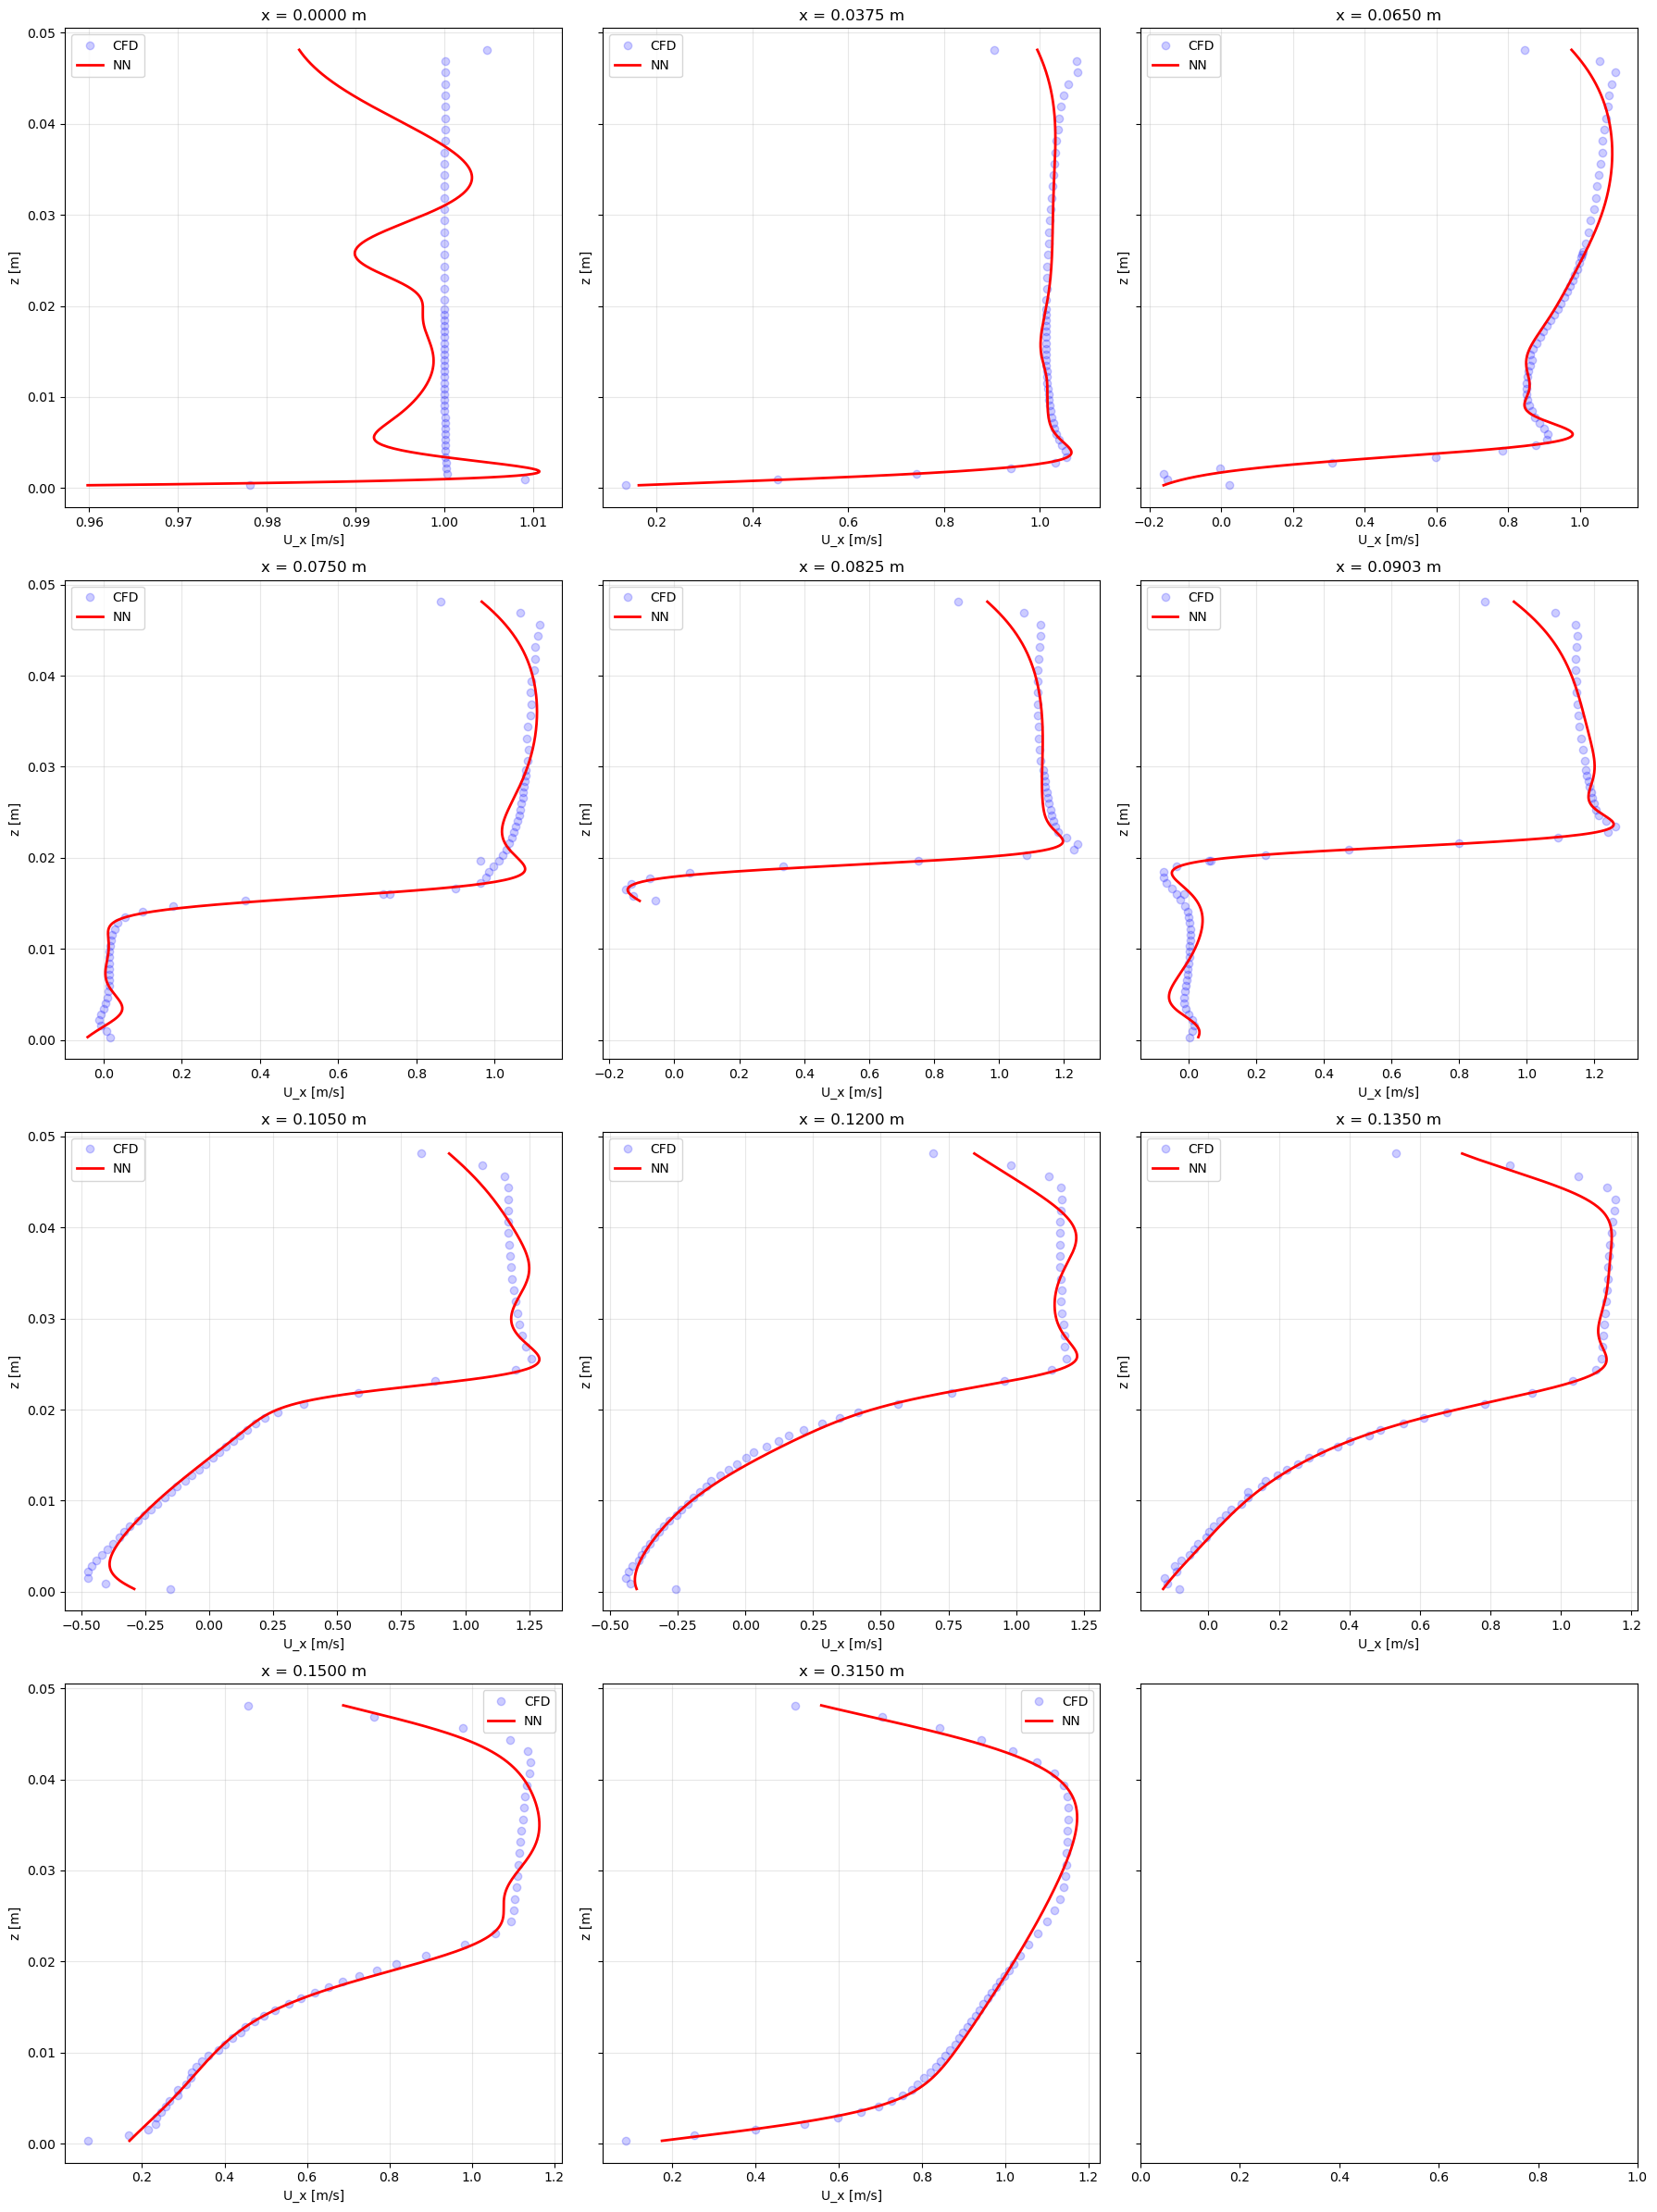

In [62]:
# VISUALIZE PREDICTIONS at all original x-locations
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 6*n_rows), 
                         squeeze=False, sharey=True)
axes = axes.flatten()

for idx, x_loc in enumerate(sorted(all_profiles.keys())):
    ax = axes[idx]
    
    # Get CFD data
    z_cfd = all_profiles[x_loc]['z']
    Ux_cfd = all_profiles[x_loc]['U_x']
    
    # Predict with unified network
    z_fine = np.linspace(z_cfd.min(), z_cfd.max(), 500)
    Ux_pred = predict_profile(model, x_loc, z_fine)
    
    # Plot
    ax.plot(Ux_cfd, z_cfd, 'bo', markersize=6, alpha=0.2, label='CFD')
    ax.plot(Ux_pred, z_fine, 'r-', linewidth=2, label='NN')
    
    ax.set_xlabel('U_x [m/s]')
    ax.set_ylabel('z [m]')
    ax.set_title(f'x = {x_loc:.4f} m')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('unified_network_predictions.png', dpi=300)
plt.show()

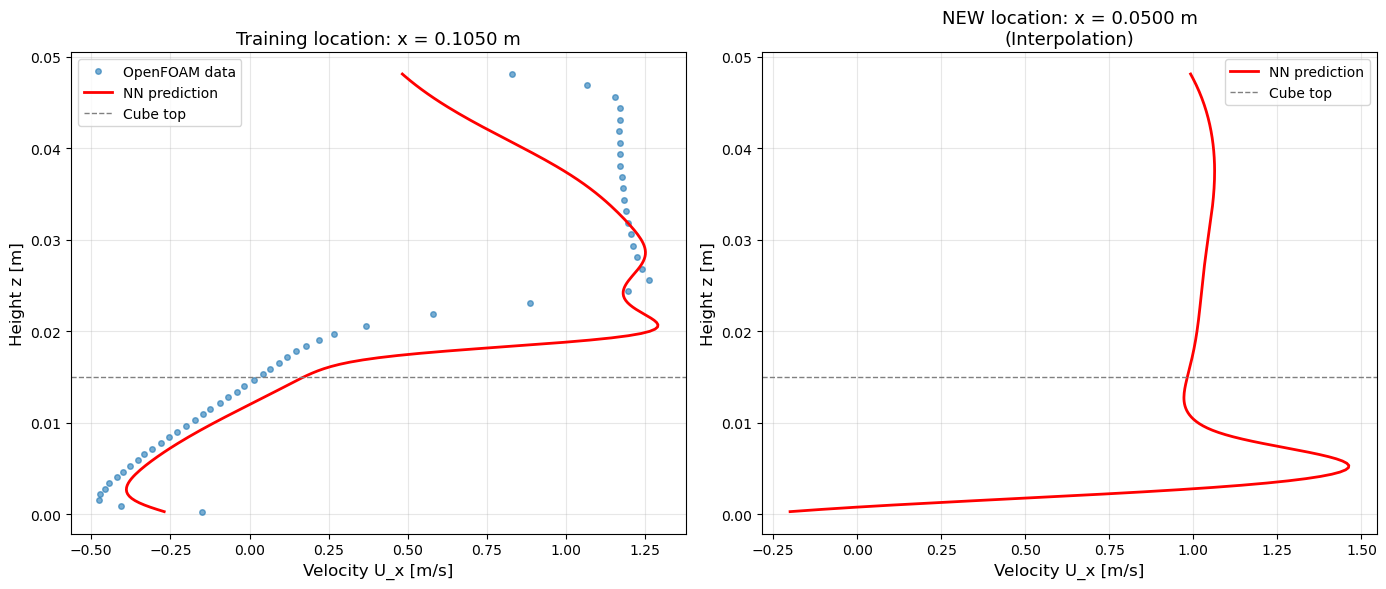

✓ Predictions plotted and saved to 'velocity_predictions.png'


In [63]:
# VISUALIZE PREDICTIONS 
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

z_fine = np.linspace(z_cfd.min(), z_cfd.max(), 200)
Ux_pred = predict_profile(model, x_loc, z_fine)
x_new = 0.05  # Between your training points
U_pred_new = predict_profile(model, x_new, z_fine, U_bulk=U_BULK_INLET)

# Plot 1: Prediction at training location
ax1 = axes[0]
if x_test in all_profiles:
    profile_data = all_profiles[x_test]
    ax1.plot(profile_data['U_x'], profile_data['z'], 'o', 
             label='OpenFOAM data', markersize=4, alpha=0.6)
    
ax1.plot(U_pred_trained, z_fine, '-', linewidth=2, 
         label='NN prediction', color='red')
ax1.axhline(y=H_CUBE, color='gray', linestyle='--', linewidth=1, label='Cube top')
ax1.set_xlabel('Velocity U_x [m/s]', fontsize=12)
ax1.set_ylabel('Height z [m]', fontsize=12)
ax1.set_title(f'Training location: x = {x_test:.4f} m', fontsize=13)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Prediction at new location
ax2 = axes[1]
ax2.plot(U_pred_new, z_fine, '-', linewidth=2, 
         label='NN prediction', color='red')
ax2.axhline(y=H_CUBE, color='gray', linestyle='--', linewidth=1, label='Cube top')
ax2.set_xlabel('Velocity U_x [m/s]', fontsize=12)
ax2.set_ylabel('Height z [m]', fontsize=12)
ax2.set_title(f'NEW location: x = {x_new:.4f} m\n(Interpolation)', fontsize=13)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('velocity_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

print("="*70)
print("✓ Predictions plotted and saved to 'velocity_predictions.png'")
print("="*70)

In [64]:
# GENERATE PREDICTIONS ON FINE GRID
    # Create continuous prediction for each trained network

print("="*70)
print("GENERATING PREDICTIONS")
print("="*70)

# Storage for predictions
predictions = {}

for x_loc, model in trained_models.items():
    print(f"Generating predictions for x = {x_loc:.4f}...")
    
    # Get normalization parameters
    z_min_norm = training_data[x_loc]['z_min']
    z_max_norm = training_data[x_loc]['z_max']
    print(f'  Normalization params: z_min={z_min_norm:.6f}, z_max={z_max_norm:.6f}')
    print(f'  Using U_bulk = {U_BULK_INLET:.4f} m/s')
    
    # Get z range for this profile
    z_full = all_profiles[x_loc]['z']
    z_min_pred = z_full.min()       # chosen values, or based on training data: z_full.min() 
    z_max_pred = z_full.max()       # chosen values, or based on training data: z_full.max() 
    print(f'  Prediction range: [{z_min_pred:.6f}, {z_max_pred:.6f}] m')    

    # Create fine grid (1000 points for smooth curve)
    z_fine = np.linspace(z_min_pred, z_max_pred, 1000)
    
    # Normalize z_fine before prediction
    z_fine_normalized = (z_fine - z_min_norm) / (z_max_norm - z_min_norm)
    
    # Create U_bulk_fine array and normalize before prediction
    U_BULK_TEST = U_BULK_INLET      # change to test for different inlet velocity
    u_bulk_fine = np.full_like(z_fine, U_BULK_TEST)
    u_bulk_fine_normalized = u_bulk_fine / U_BULK_TEST
    
    # Stack into 2D [z, U_bulk] for fine prediction
    X_fine_stacked = np.column_stack([z_fine_normalized, u_bulk_fine_normalized])
    
    # Predict
    z_tensor = torch.tensor(X_fine_stacked, dtype=torch.float32)
    
    model.eval()
    with torch.no_grad():
        Ux_pred = model(z_tensor).numpy().flatten()
    
    # Store
    predictions[x_loc] = {
        'z_fine': z_fine,
        'Ux_pred': Ux_pred
    }
    
    print(f"  ✓ {len(z_fine)} prediction points generated")
    print(f"    U_x range: [{Ux_pred.min():.4f}, {Ux_pred.max():.4f}] m/s\n")

print("="*70)
print(f"✓ Predictions generated for all {len(predictions)} profiles")
print("="*70 + "\n")

GENERATING PREDICTIONS


NameError: name 'trained_models' is not defined

Creating prediction visualization...


KeyError: 'z_train'

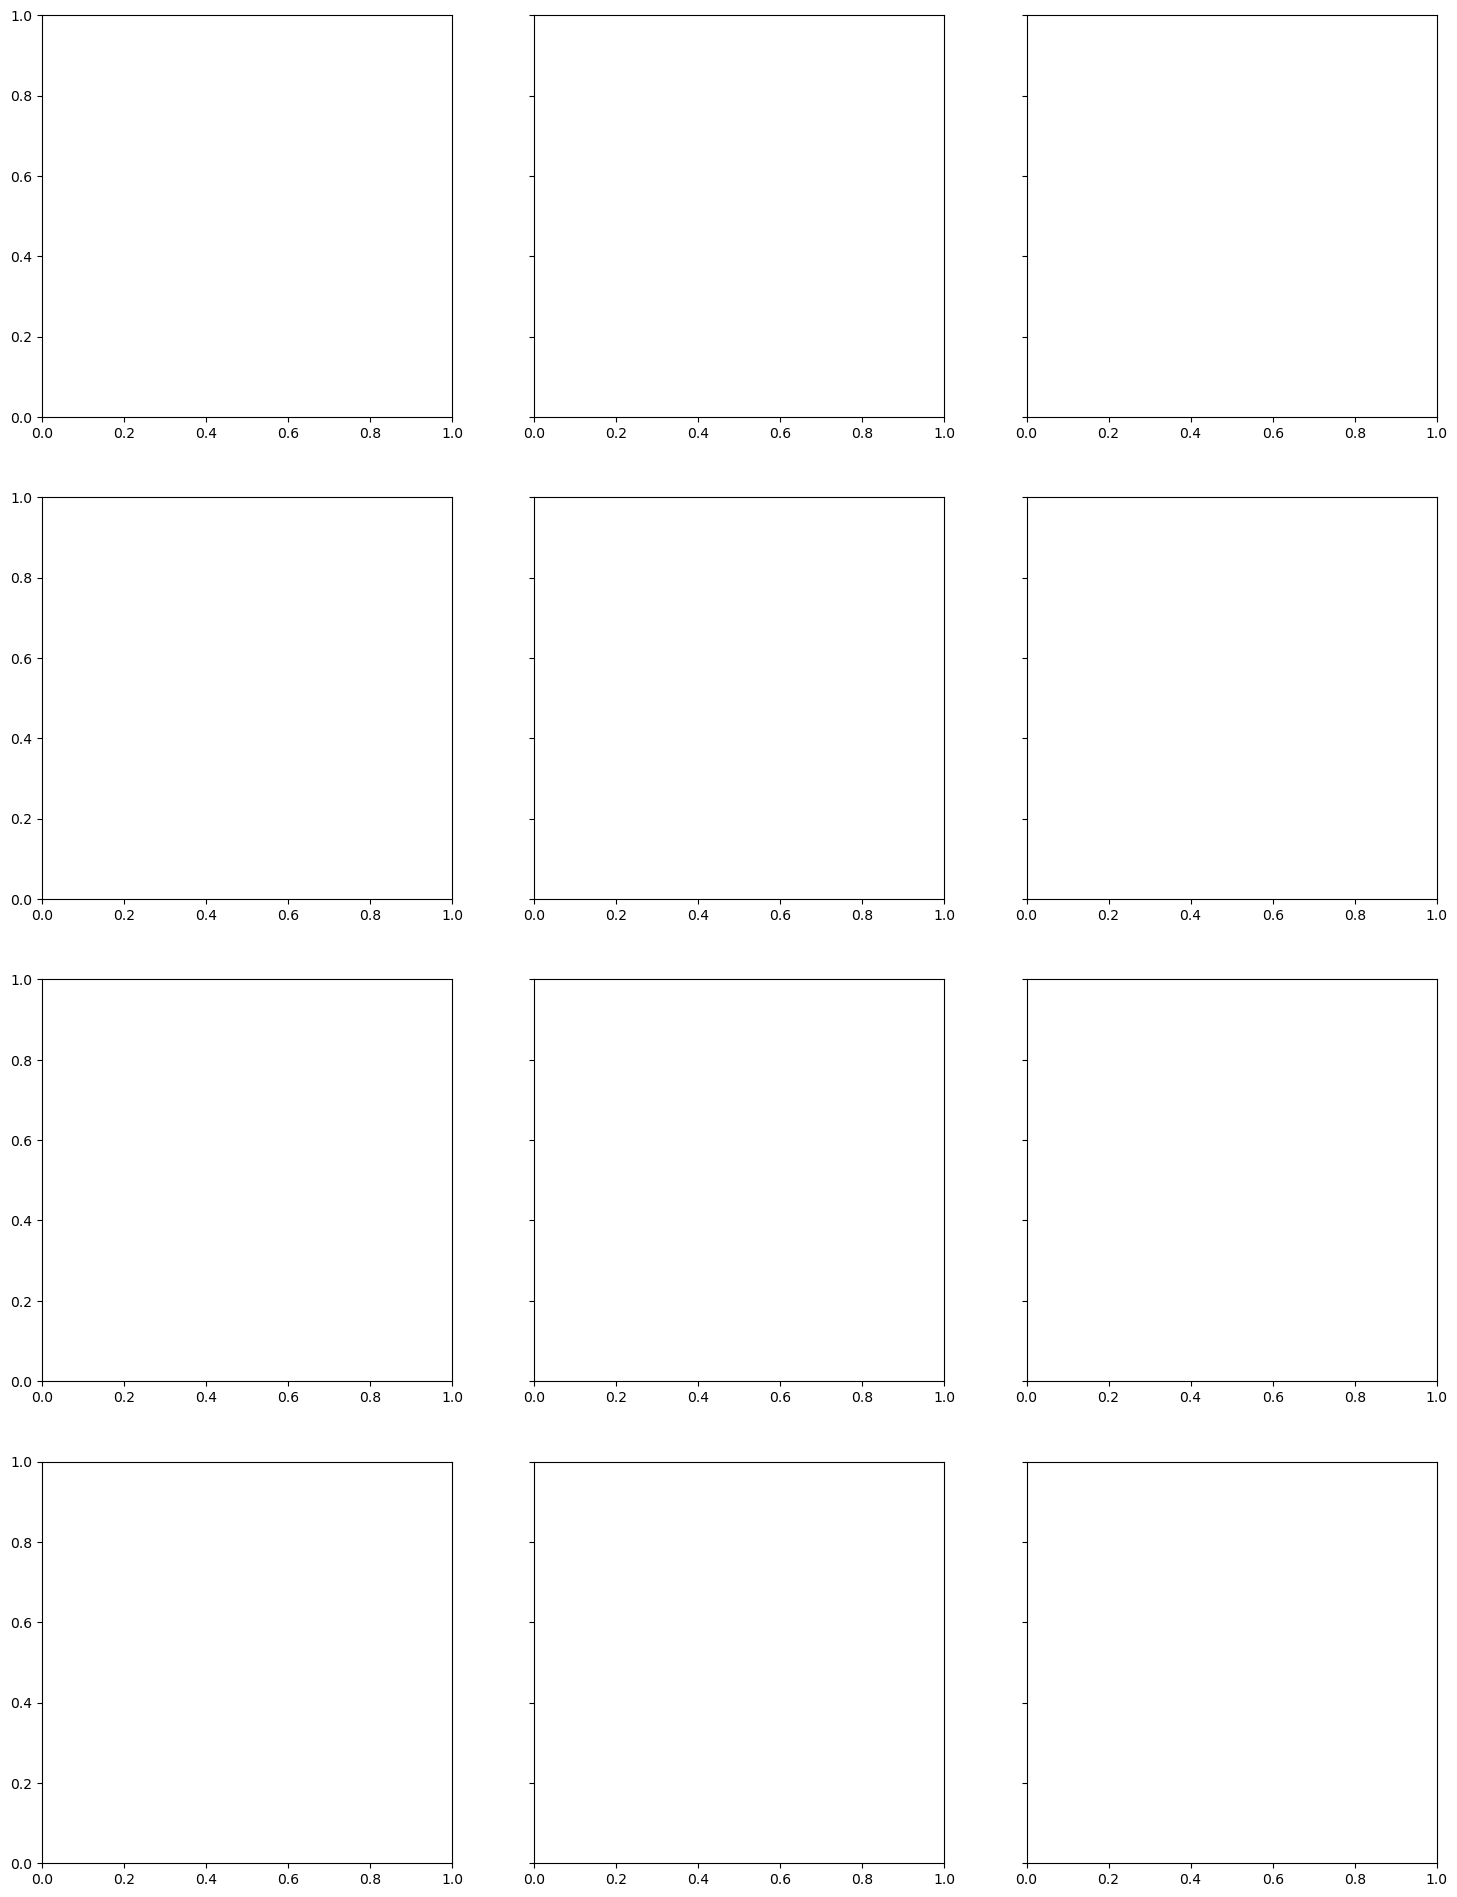

In [65]:
# VISUALIZE PREDICTIONS
     # Compare training data with network predictions


print("Creating prediction visualization...")

n_profiles = len(all_profiles)
n_cols = min(3, n_profiles)
n_rows = int(np.ceil(n_profiles / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 6*n_rows), 
                         squeeze=False, sharey=True)
axes = axes.flatten()

for idx, (x_loc, profile_data) in enumerate(all_profiles.items()):
    ax = axes[idx]
    
    # Get data
    z_full = profile_data['z']
    Ux_full = profile_data['U_x']
    
    z_train = training_data[x_loc]['z_train']
    Ux_train = training_data[x_loc]['Ux_train']
    
    # Get predictions
    z_fine = predictions[x_loc]['z_fine']
    Ux_pred = predictions[x_loc]['Ux_pred']
    
    # Plot
    ax.plot(Ux_full, z_full, 'k.', markersize=2, alpha=0.2, label='All CFD data')
    ax.plot(Ux_train, z_train, 'bo', markersize=6, markeredgewidth=1.5,
            label=f'Training ({len(z_train)} pts)', zorder=3)
    ax.plot(Ux_pred, z_fine, 'r^--', linewidth=2.5, label='NN prediction', zorder=2)
    
    # Labels
    ax.set_xlabel('U_x [m/s]', fontsize=11)
    if idx % n_cols == 0:
        ax.set_ylabel('z [m]', fontsize=11)
    
    # Title with RMSE
    rmse = training_histories[x_loc]['rmse']
    ax.set_title(f'x = {x_loc:.4f} m\nRMSE: {rmse:.4f} m/s\nMAE: {mae:.4f} m/s', 
                 fontsize=12, fontweight='bold')
    
    ax.legend(fontsize=9, loc='best')
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for idx in range(n_profiles, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Network Predictions vs Training Data', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Predictions_comparison_ADAM_Multiple_Normalized_Ubulk.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: Predictions_comparison_ADAM_Multiple_Normalized_Ubulk.png\n")

Creating error comparison...


NameError: name 'training_histories' is not defined

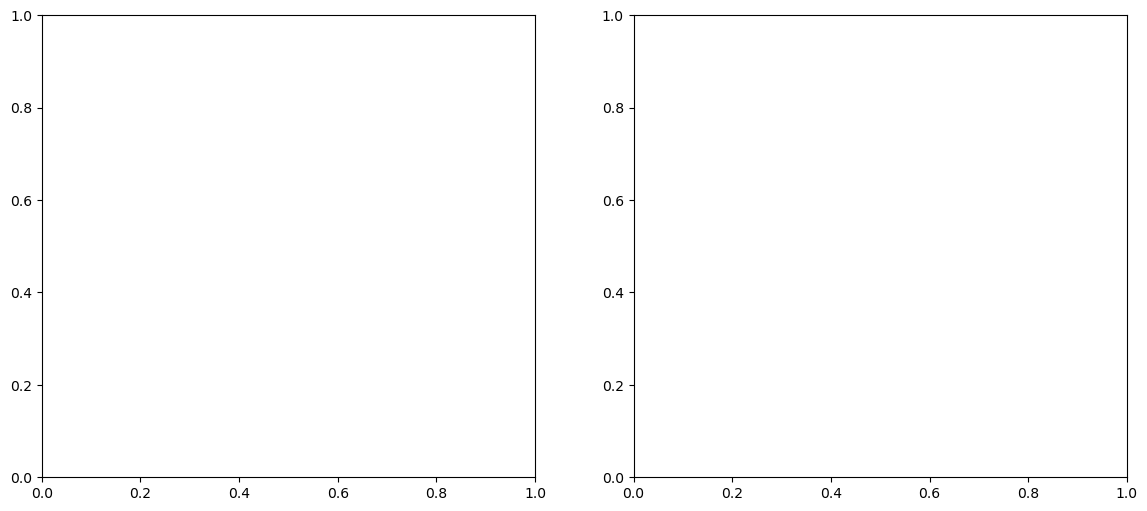

In [66]:
# ERROR ANALYSIS ACROSS ALL PROFILES
    # Compare error distributions

print("Creating error comparison...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ============================================
# Plot 1: Error Distribution for Each Profile
# ============================================

for x_loc, eval_data in training_histories.items():
    errors = eval_data['errors']
    z_train = training_data[x_loc]['z_train']
    
    axes[0].plot(errors, z_train, 'o-', markersize=4, 
                label=f'x={x_loc:.3f}', alpha=0.7)

axes[0].axvline(x=0, color='k', linestyle='--', linewidth=2, alpha=0.5)
axes[0].set_xlabel('Error (CFD - NN) [m/s]', fontsize=12)
axes[0].set_ylabel('z [m]', fontsize=12)
axes[0].set_title('Error Distribution - All Profiles', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=9, loc='best')
axes[0].grid(True, alpha=0.3)

# ============================================
# Plot 2: Error Statistics Comparison
# ============================================

x_locs = list(training_histories.keys())
rmses = [training_histories[x]['rmse'] for x in x_locs]
maes = [training_histories[x]['mae'] for x in x_locs]
max_errors = [training_histories[x]['max_error'] for x in x_locs]

x_pos = np.arange(len(x_locs))
width = 0.25

bars1 = axes[1].bar(x_pos - width, rmses, width, label='RMSE', alpha=0.8, color='blue')
bars2 = axes[1].bar(x_pos, maes, width, label='MAE', alpha=0.8, color='green')
bars3 = axes[1].bar(x_pos + width, max_errors, width, label='Max Error', alpha=0.8, color='red')

axes[1].set_xlabel('x-location', fontsize=12)
axes[1].set_ylabel('Error [m/s]', fontsize=12)
axes[1].set_title('Error Metrics by Location', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f'{x:.3f}' for x in x_locs], rotation=45, ha='right')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('Error_comparison_ADAM_Multiple_Normalized_Ubulk.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: Error_comparison_ADAM_Multiple_Normalized_Ubulk.png\n")